In [33]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from tkinter import Tk, filedialog
from matplotlib.patches import Rectangle

Выбор файла

In [5]:
root = Tk()
root.withdraw()
file_name = filedialog.askopenfilename(title = 'Выберите файл',
                                        filetypes = [('CSV файлы', '*.csv')])
root.destroy()

if not file_name:
    print('Файл не выбран')
    raise SystemExit
print(file_name)

C:/python/ML/lab1/lab1_DS.csv


Чтение данных из файла

In [6]:
df = pd.read_csv(file_name, sep = None, engine = 'python')
print(df.head())

   YearsExperience  Salary
0              1.1   39343
1              1.3   46205
2              1.5   37731
3              2.0   43525
4              2.2   39891


Информация о данных

In [7]:
print(df.describe())

       YearsExperience         Salary
count        35.000000      35.000000
mean          6.308571   83945.600000
std           3.618610   32162.673003
min           1.100000   37731.000000
25%           3.450000   57019.000000
50%           5.300000   81363.000000
75%           9.250000  113223.500000
max          13.500000  139465.000000


Выбор столбцов

In [8]:
columns = list(df.select_dtypes(include = 'number').columns)
for i, name in enumerate(columns):
    print(i, name)

0 YearsExperience
1 Salary


In [15]:
x_num = int(input('Номер столбца X: '))
y_num = int(input('Номер столбца Y: '))
print(f'Столбец X: {columns[x]}\nСтолбец Y: {columns[y]}')

Столбец X: YearsExperience
Столбец Y: Salary


Подгатавливаем данные

In [20]:
points = df[[columns[x_num], columns[y_num]]].dropna() # Убираем лишние столбцы
x = points[columns[x_num]].to_numpy() # Преобразуем столбцы в массив numpy
y = points[columns[y_num]].to_numpy()
print(points)

    YearsExperience  Salary
0               1.1   39343
1               1.3   46205
2               1.5   37731
3               2.0   43525
4               2.2   39891
5               2.9   56642
6               3.0   60150
7               3.2   54445
8               3.2   64445
9               3.7   57189
10              3.9   63218
11              4.0   55794
12              4.0   56957
13              4.1   57081
14              4.5   61111
15              4.9   67938
16              5.1   66029
17              5.3   83088
18              5.9   81363
19              6.0   93940
20              6.8   91738
21              7.1   98273
22              7.9  101302
23              8.2  113812
24              8.7  109431
25              9.0  105582
26              9.5  116969
27              9.6  112635
28             10.3  122391
29             10.5  121872
30             11.2  127345
31             11.5  126756
32             12.3  128765
33             12.9  135675
34             13.5 

Метод наименьших квадратов

In [29]:
a = np.sum((x - x.mean()) * (y - y.mean())) / np.sum((x - x.mean())**2)
b = y.mean() - a * x.mean()
y_pred = a * x + b
print(f'Уравнение прямой: y = {a:.4f} * x + {b:.4f}')

Уравнение прямой: y = 8731.9410 * x + 28859.5262


Изображения

Text(0.5, 1.0, 'Квадраты ошибок')

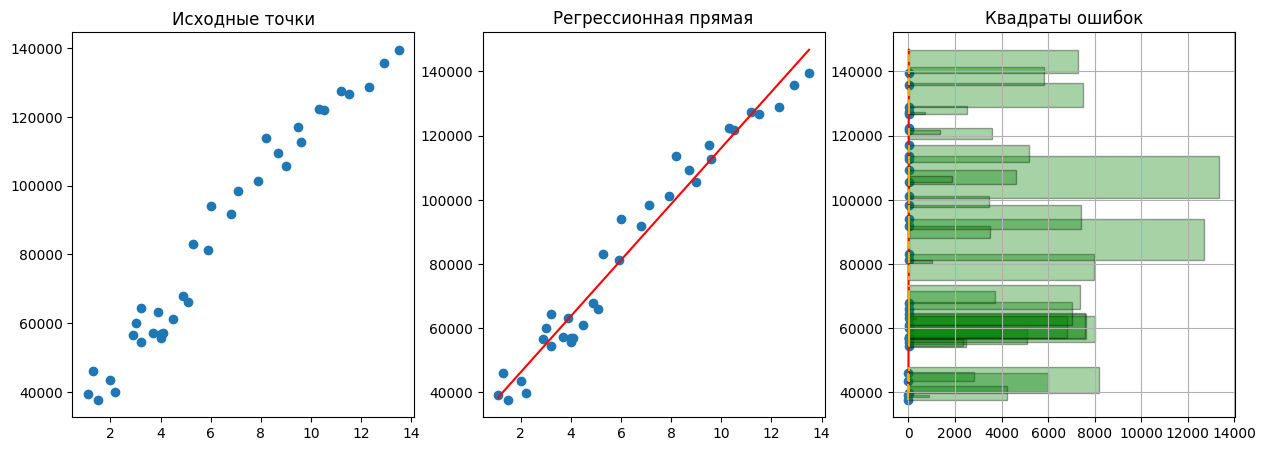

In [37]:
fig, ax = plt.subplots(1, 3, figsize = (15, 5))

ax[0].scatter(x, y)
ax[0].set_title('Исходные точки')

ax[1].scatter(x, y)
order = np.argsort(x)
ax[1].plot(x[order], y_pred[order], color = 'red')
ax[1].set_title('Регрессионная прямая')

ax[2].scatter(x, y)
ax[2].plot(x, a * x + b, color = 'red')

for xi, yi in zip(x, y):
    y_pr = a * xi + b
    error = abs(yi - y_pr)
    square = Rectangle((xi, min(yi, y_pr)), 
                        error, 
                        error, 
                        facecolor = 'green',
                        edgecolor = 'black',
                        alpha = 0.35)

    ax[2].add_patch(square)
    ax[2].plot([xi, xi],
                [yi, y_pr],
                color = 'orange',
                linestyle = '--')

ax[2].grid(True)
ax[2].set_title('Квадраты ошибок')